# Data Ingestion

In [10]:
import pandas as pd
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
from scipy import stats

## Configuration & Constants

In [11]:
# --- Global Settings for Easy Modification ---
FIG_SIZE_SINGLE = (10, 7)     
FIG_SIZE_MULTI = (18, 14)     # Increased size for better padding
FONT_SCALE = 2.0
DPI = 300

# Define consistent colors for models
MODEL_NAME_MAPPING = {
    'x-ai/grok-4-fast': 'Grok',
    'openai/gpt-5-nano': 'ChatGPT',
    'google/gemini-2.5-flash': 'Gemini',
    'deepseek/deepseek-chat-v3.1': 'DeepSeek'
}

# Create a consistent color palette
unique_models = sorted(list(MODEL_NAME_MAPPING.values()))
_palette_raw = sns.color_palette("tab10", n_colors=len(unique_models))
MODEL_COLORS = dict(zip(unique_models, _palette_raw))

# Publication-ready style
sns.set_style("white")
sns.set_context("paper", font_scale=FONT_SCALE)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = DPI

## Data Loading

In [12]:
strategies = {
    'strategy_one': 'strategy_one_results',
    'strategy_two': 'strategy_two_results',
    'strategy_three': 'strategy_three_results',
    'strategy_four': 'strategy_four_results'
}

all_dfs = []

for strategy_name, directory in strategies.items():
    dir_path = os.path.join('.', directory)
    if not os.path.exists(dir_path):
        print(f"Warning: Directory '{dir_path}' not found. Skipping...")
        continue
        
    csv_files = glob.glob(os.path.join(dir_path, 'results_*.csv'))
    
    for csv_file in csv_files:
        filename = os.path.basename(csv_file)
        df = pd.read_csv(csv_file)
        df['strategy'] = strategy_name
        all_dfs.append(df)

if all_dfs:
    results_df = pd.concat(all_dfs, ignore_index=True)
    print(f"Successfully combined {len(all_dfs)} files. Total rows: {len(results_df)}")
else:
    print("No data files were found or loaded.")
    results_df = pd.DataFrame() 

if not results_df.empty:
    results_df['model'] = results_df['model'].replace(MODEL_NAME_MAPPING)
    results_df['npi_preference'] = results_df['npi_level_selected'] - results_df['npi_level_non_selected']
    results_df['infection_preference'] = results_df['infection_rate_selected'] - results_df['infection_rate_non_selected']
    '''
    results_df['irrational_choice'] = (
        ((results_df['infection_rate_selected'] > results_df['infection_rate_non_selected']) &
         (results_df['npi_level_selected'] >= results_df['npi_level_non_selected'])) |
        ((results_df['npi_level_selected'] > results_df['npi_level_non_selected']) &
         (results_df['infection_rate_selected'] <= results_df['infection_rate_non_selected']))
    )
    '''
    results_df['irrational_choice'] = ((results_df['infection_rate_selected'] > results_df['infection_rate_non_selected']) &
         (results_df['npi_level_selected'] >= results_df['npi_level_non_selected']))

Successfully combined 16 files. Total rows: 6336


# Helper Functions

In [13]:
def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    strategy_lower = str(strategy_name).lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    return 0

def add_panel_labels(axes, x_offset=-0.02, y_offset=1.05):
    """
    Add letter labels (A, B, C...) to subplots.
    Moved x_offset further left (-0.15) to keep clear of y-axis labels.
    """
    axes_flat = axes.flatten() if isinstance(axes, np.ndarray) else [axes]
    for i, ax in enumerate(axes_flat):
        if ax.get_visible():
            label = string.ascii_uppercase[i]
            ax.text(x_offset, y_offset, label, transform=ax.transAxes,
                    fontsize=26, fontweight='bold', va='bottom', ha='right')

def save_publication_figure(filename_base):
    """Display figure instead of saving."""
    plt.show()

def get_context_column(strategy_name):
    strategy_num = extract_strategy_number(strategy_name)
    context_mapping = {
        2: 'capacity_context',
        3: 'economic_context',
        4: 'user_preference_type'
    }
    return context_mapping.get(strategy_num, None)

def get_legend_title(context_col):
    if not context_col: return None
    title_mapping = {
        'capacity_context': 'Capacity Context',
        'economic_context': 'Economic Context',
        'user_preference_type': 'User Preference'
    }
    return title_mapping.get(context_col, context_col.replace('_', ' ').title())

# Analysis & Figures

### Figure 1: % Irrational Choice (Combined)

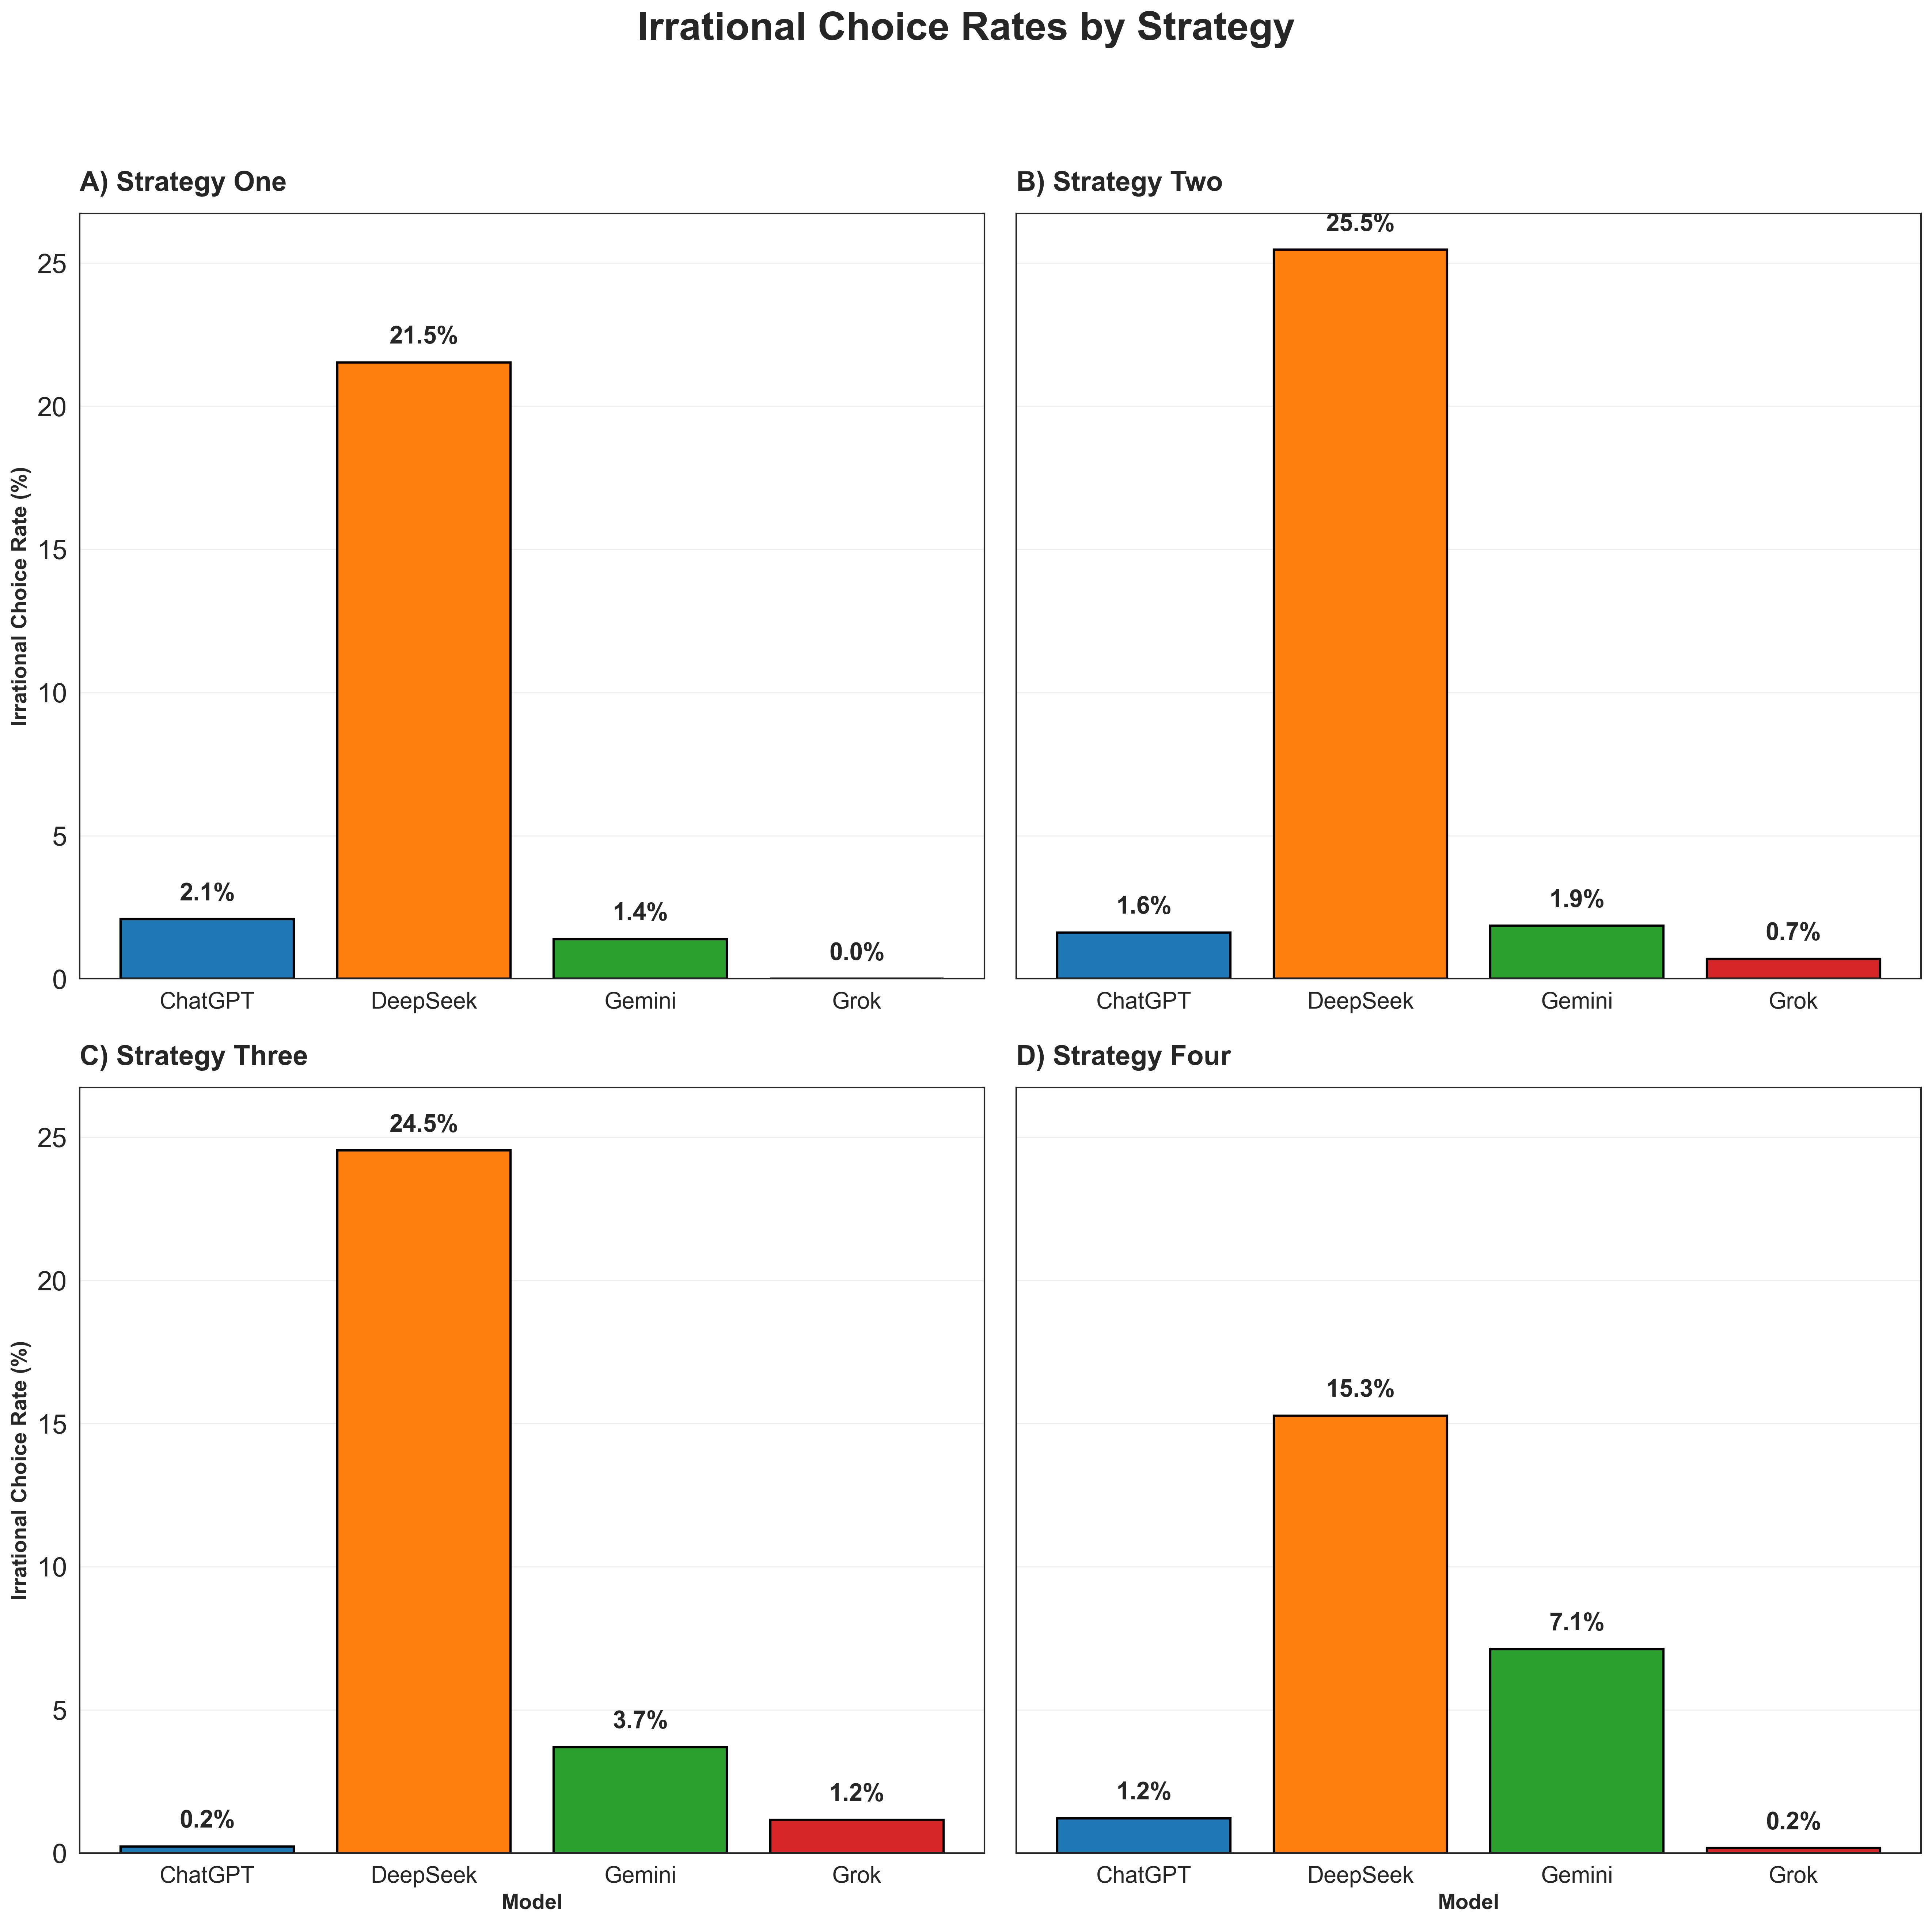

In [14]:
def plot_irrational_choice_combined(df):
    """Figure 1: Multi-panel bar chart of irrational choices."""
    
    freq_data = df.groupby(['strategy', 'model'])['irrational_choice'].agg([
        ('irrational_rate', 'mean')
    ]).reset_index()
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100
    
    strategies = sorted(freq_data['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    # Increased height slightly to help with Panel C label issue
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 18), sharex=True, sharey=True)
    axes_flat = axes.flatten()
    
    for idx, strategy in enumerate(strategies):
        ax = axes_flat[idx]
        strategy_data = freq_data[freq_data['strategy'] == strategy].sort_values('model')
        
        bars = ax.bar(
            strategy_data['model'],
            strategy_data['irrational_percentage'],
            color=[MODEL_COLORS[m] for m in strategy_data['model']],
            edgecolor='black',
            linewidth=1.5
        )
        
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=16, fontweight='bold')
        
        ax.set_title(f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}', fontsize=18, fontweight='bold', loc='left', pad=15)
        ax.grid(axis='y', alpha=0.3)
        
        # ENABLE LABELS ON ALL PANELS (Specific model names)
        ax.tick_params(axis='x', rotation=0, labelsize=15, labelbottom=True)
        
    # Y-axis labels on the left column
    # Handle 1D array case (if n_rows=1) vs 2D array
    if axes.ndim == 1:
        axes[0].set_ylabel('Irrational Choice Rate (%)', fontsize=14, fontweight='bold')
    else:
        for ax in axes[:, 0]: 
            ax.set_ylabel('Irrational Choice Rate (%)', fontsize=14, fontweight='bold')

    # MODIFIED: X-axis labels ('Model') ONLY on the bottom panels
    if axes.ndim == 1:
        bottom_row = axes
    else:
        bottom_row = axes[-1, :]
        
    for ax in bottom_row: 
        ax.set_xlabel('Model', fontsize=14, fontweight='bold')

    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    fig.suptitle('Irrational Choice Rates by Strategy', fontsize=26, fontweight='bold', y=0.98)
    
    plt.tight_layout(rect=[0, 0, 1, 0.95]) 
    save_publication_figure('fig1_irrational_choices_combined')
    #plt.show()


if not results_df.empty:
    plot_irrational_choice_combined(results_df)


### Figure 2 & 3: Error Bar Plots (Mean Preferences)

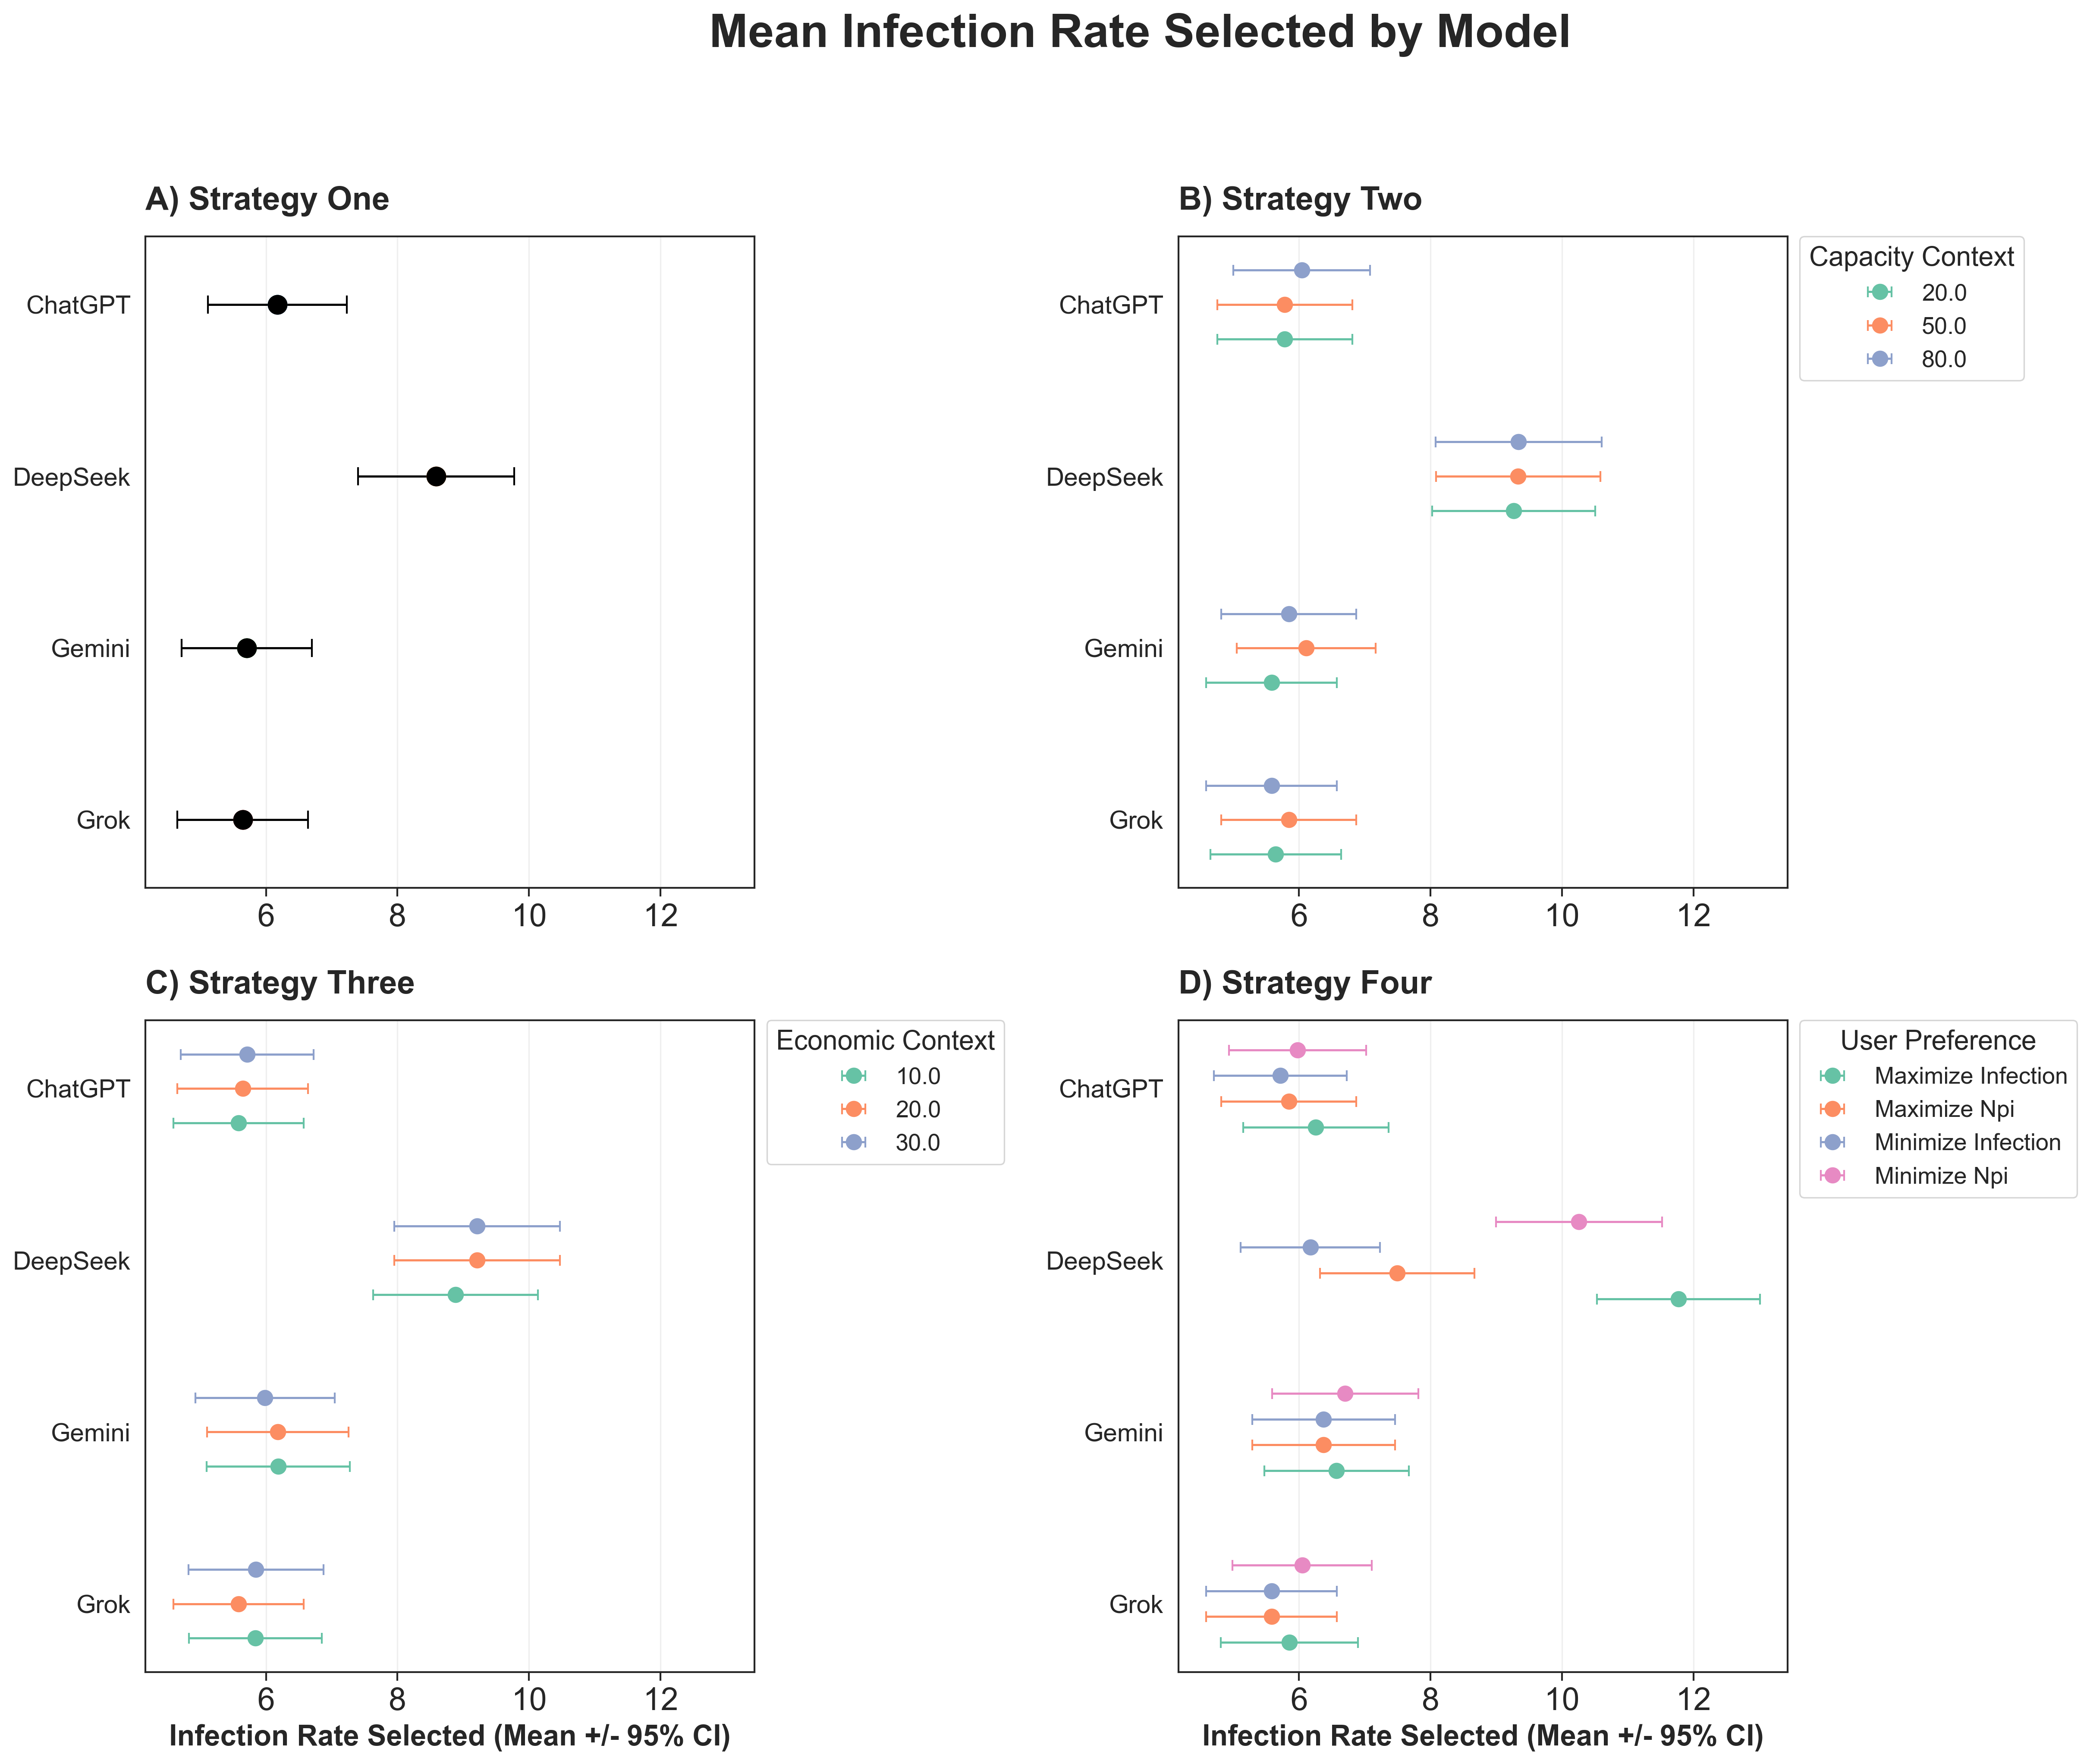

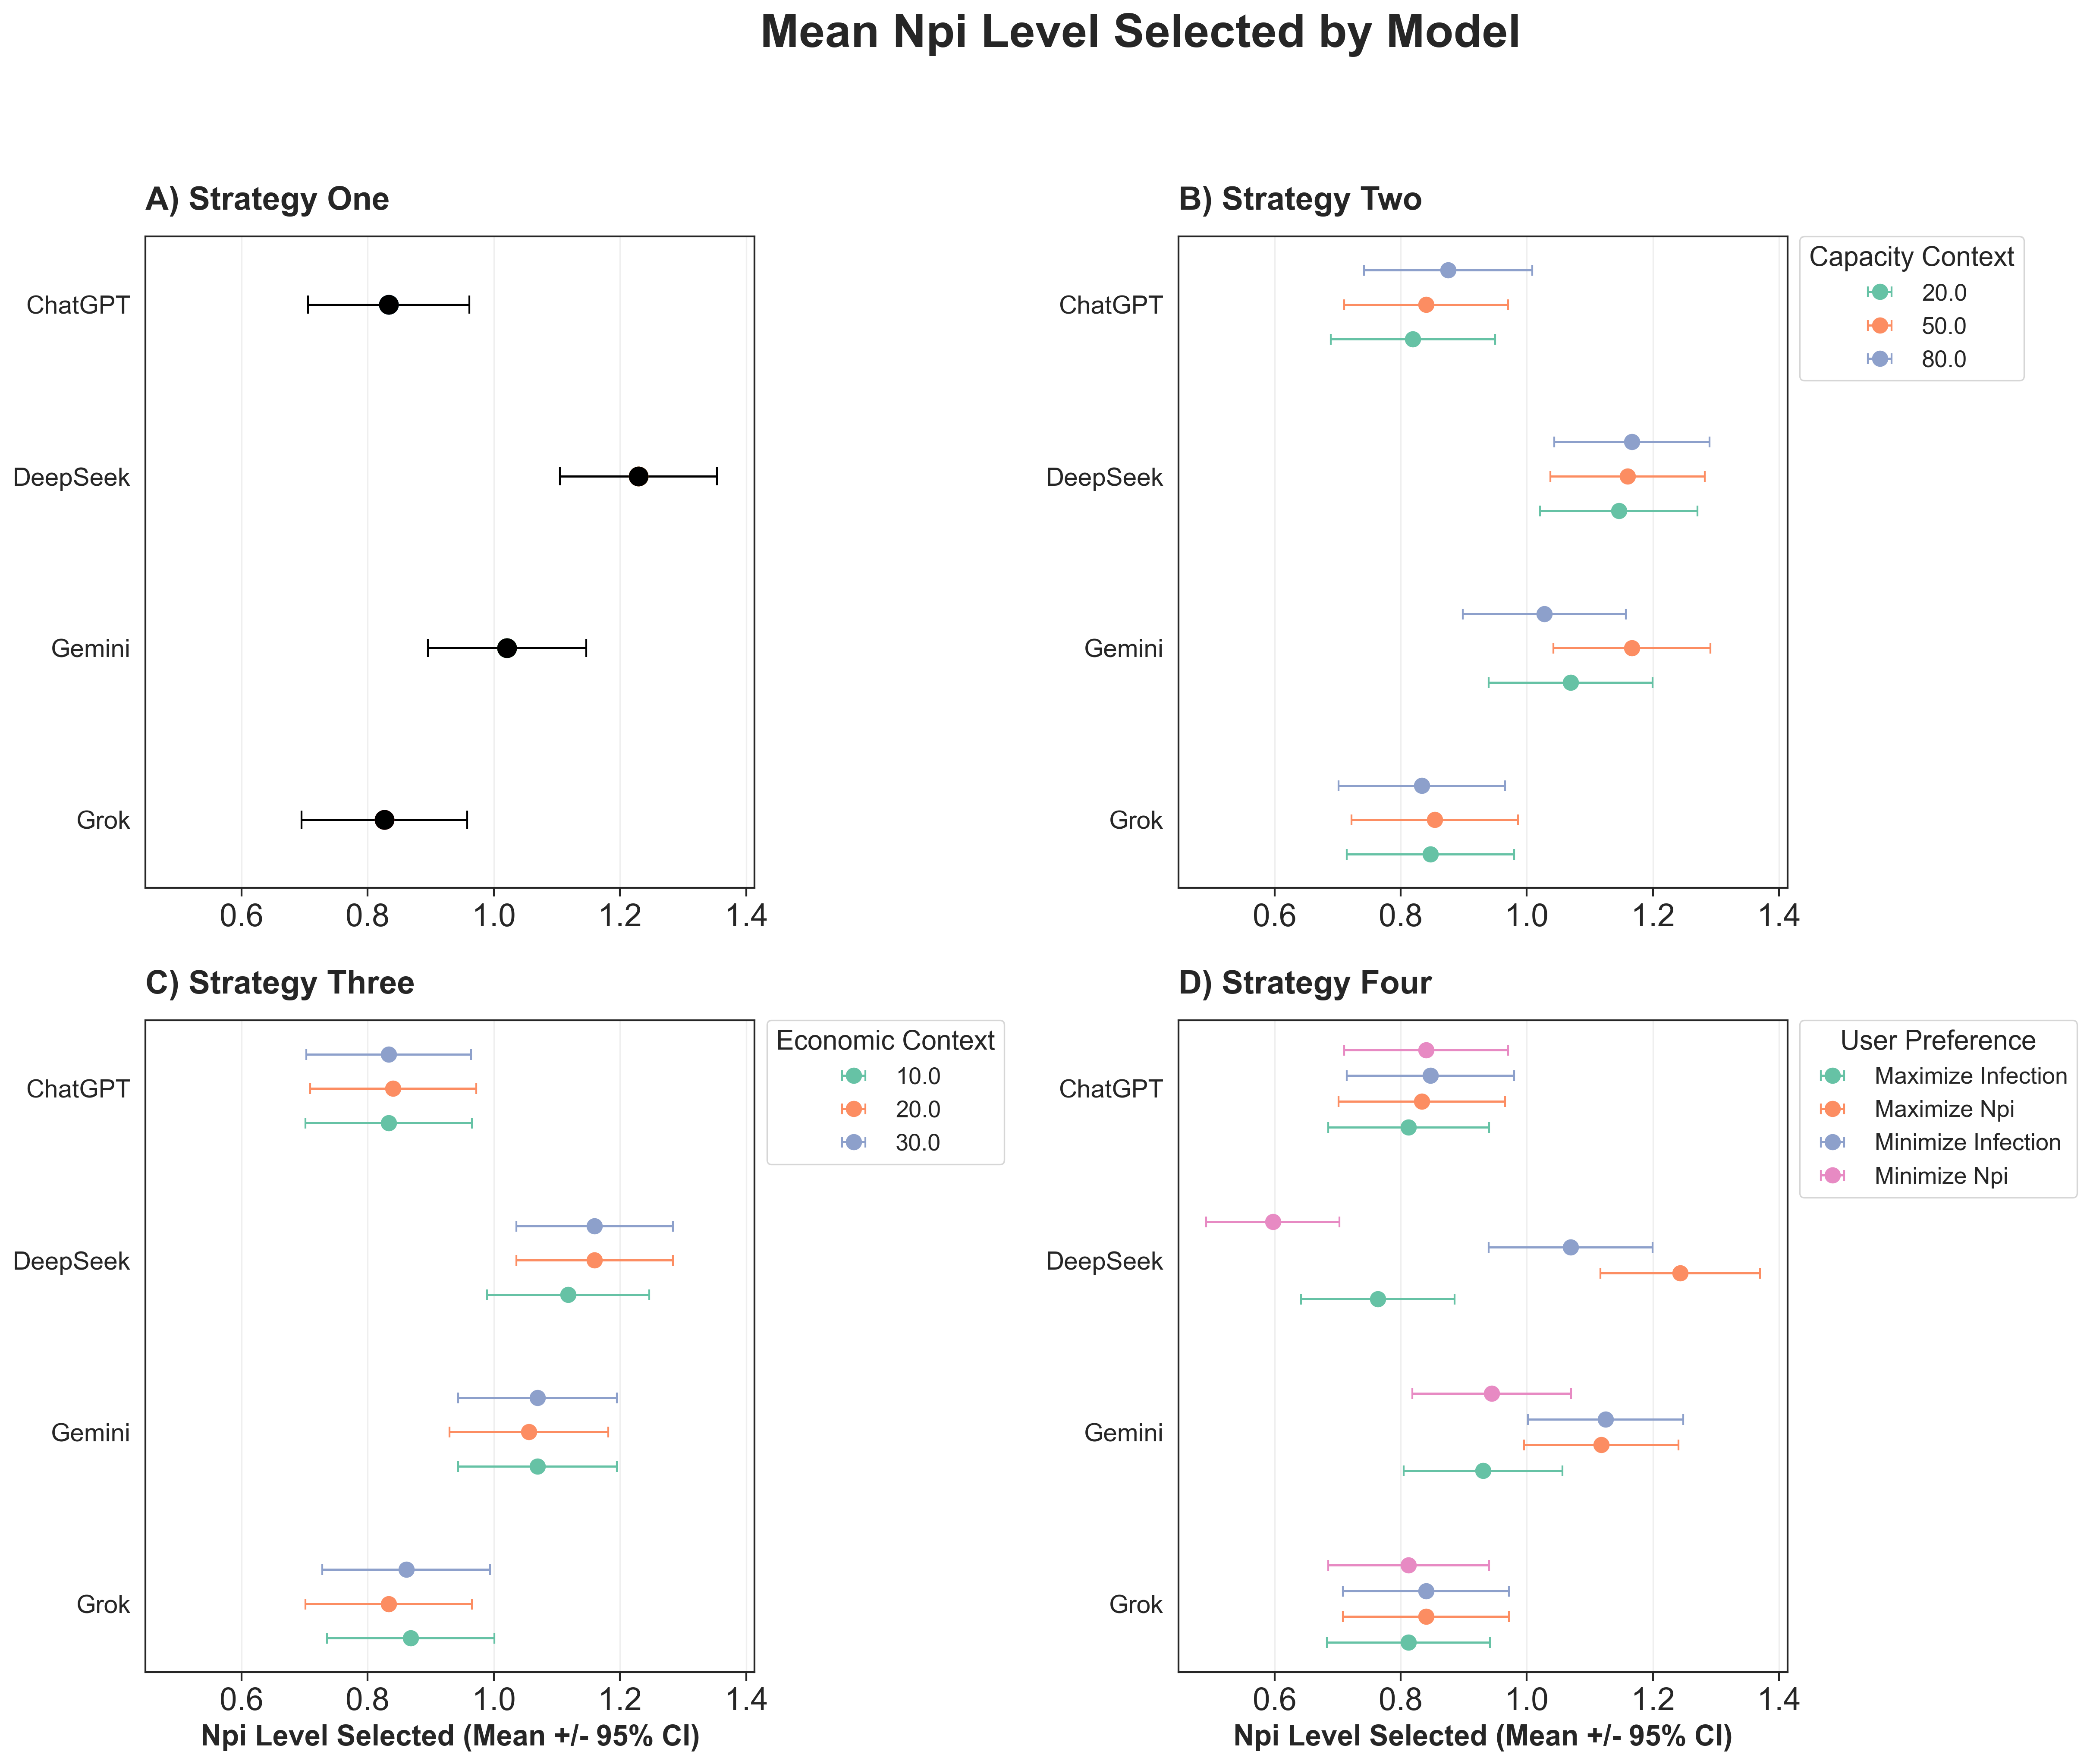

In [15]:
def calculate_errorbar_data(df, response_col, context_cols, use_percentage=False):
    grouped = df.groupby(context_cols)[response_col]
    plot_data = []
    for name, group in grouped:
        if len(group) > 0:
            data = group.values
            if use_percentage: data = data * 100
            mean_val = data.mean()
            if len(data) > 1:
                ci = stats.t.interval(0.95, len(data) - 1, loc=mean_val, scale=stats.sem(data))
                ci_lower, ci_upper = mean_val - ci[0], ci[1] - mean_val
            else:
                ci_lower, ci_upper = 0, 0
                
            record = {}
            if isinstance(name, tuple):
                for i, col in enumerate(context_cols): record[col] = name[i]
            else:
                record[context_cols[0]] = name
            record['mean'] = mean_val
            record['ci_lower'] = ci_lower
            record['ci_upper'] = ci_upper
            plot_data.append(record)
    return pd.DataFrame(plot_data)


def plot_combined_errorbar(df, response_col, parameter_col, figure_name, use_percentage=False):
    """
    Generic function for Fig 2 and 3.
    Shows labels on ALL y-axes.
    """
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    # MODIFIED: reverse=True ensures 'A' is at the top (highest y-index) and 'Z' is at the bottom (index 0)
    global_param_order = sorted(df[parameter_col].unique(), reverse=True)
    
    # sharey=True keeps scales same, but we will manually enable tick labels
    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()
    
    for idx, strategy in enumerate(strategies):
        ax = axes_flat[idx]
        strategy_data = df[df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)
        
        if context_col and context_col in strategy_data.columns:
            group_cols = [parameter_col, context_col]
        else:
            group_cols = [parameter_col]
            
        plot_df = calculate_errorbar_data(strategy_data, response_col, group_cols, use_percentage)
        if plot_df.empty: continue
        
        if len(group_cols) == 1:
            plot_df = plot_df.set_index(parameter_col).reindex(global_param_order).reset_index()
            y_positions = range(len(plot_df))
            ax.errorbar(
                plot_df['mean'], y_positions,
                xerr=[plot_df['ci_lower'], plot_df['ci_upper']],
                fmt='o', markersize=10, color='black', capsize=5
            )
            if parameter_col == 'model':
                for y, model_name in zip(y_positions, plot_df['model']):
                    if model_name in MODEL_COLORS:
                        ax.plot(plot_df.loc[plot_df['model']==model_name, 'mean'], y, 
                                'o', color=MODEL_COLORS[model_name], markersize=10)
            ax.set_yticks(list(y_positions))
            ax.set_yticklabels(plot_df[parameter_col], fontsize=14)
        else:
            secondary_col = context_col
            secondary_values = sorted(plot_df[secondary_col].unique())
            context_colors = sns.color_palette("Set2", len(secondary_values))
            
            for i, sec_val in enumerate(secondary_values):
                subset = plot_df[plot_df[secondary_col] == sec_val]
                subset = subset.set_index(parameter_col).reindex(global_param_order)
                y_base = np.arange(len(global_param_order))
                
                # Small offsets to group bars
                bar_height = 0.6
                bar_spacing = bar_height / max(1, len(secondary_values))
                y_offset = (i - len(secondary_values)/2 + 0.5) * bar_spacing
                y_final = y_base + y_offset
                
                ax.errorbar(
                    subset['mean'], y_final,
                    xerr=[subset['ci_lower'], subset['ci_upper']],
                    fmt='o', markersize=8, 
                    color=context_colors[i],
                    label=str(sec_val).replace('_', ' ').title(),
                    capsize=3
                )
            ax.set_yticks(np.arange(len(global_param_order)))
            ax.set_yticklabels(global_param_order, fontsize=14)
            legend_title = get_legend_title(context_col)
            ax.legend(title=legend_title, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=13, title_fontsize=15)


        ax.set_title(f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}', fontsize=18, fontweight='bold', loc='left', pad=15)
        ax.grid(axis='x', alpha=0.3)
        
        # FORCE LABELS ON ALL PANELS
        ax.tick_params(axis='y', labelleft=True)
        ax.tick_params(axis='x', bottom=True, labelbottom=True)
    
    # MODIFIED: Labels ONLY on the bottom panels
    xlabel = f'{response_col.replace("_", " ").title()} (Mean +/- 95% CI)'
    if axes.ndim == 1:
        bottom_row = axes
    else:
        bottom_row = axes[-1, :]

    for ax in bottom_row: 
        ax.set_xlabel(xlabel, fontsize=16, fontweight='bold')
    
    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)
        
    clean_title = response_col.replace('_', ' ').title()
    fig.suptitle(f'Mean {clean_title} by Model', fontsize=26, fontweight='bold', y=0.98)


    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    save_publication_figure(figure_name)
    #plt.show()


if not results_df.empty:
    # Figure 2: Infection Mean
    plot_combined_errorbar(results_df, 'infection_rate_selected', 'model', 'fig2_infection_mean')
    # Figure 3: NPI Mean
    plot_combined_errorbar(results_df, 'npi_level_selected', 'model', 'fig3_npi_mean')


### Figure 4: Scatter Plot (Infection vs NPI)

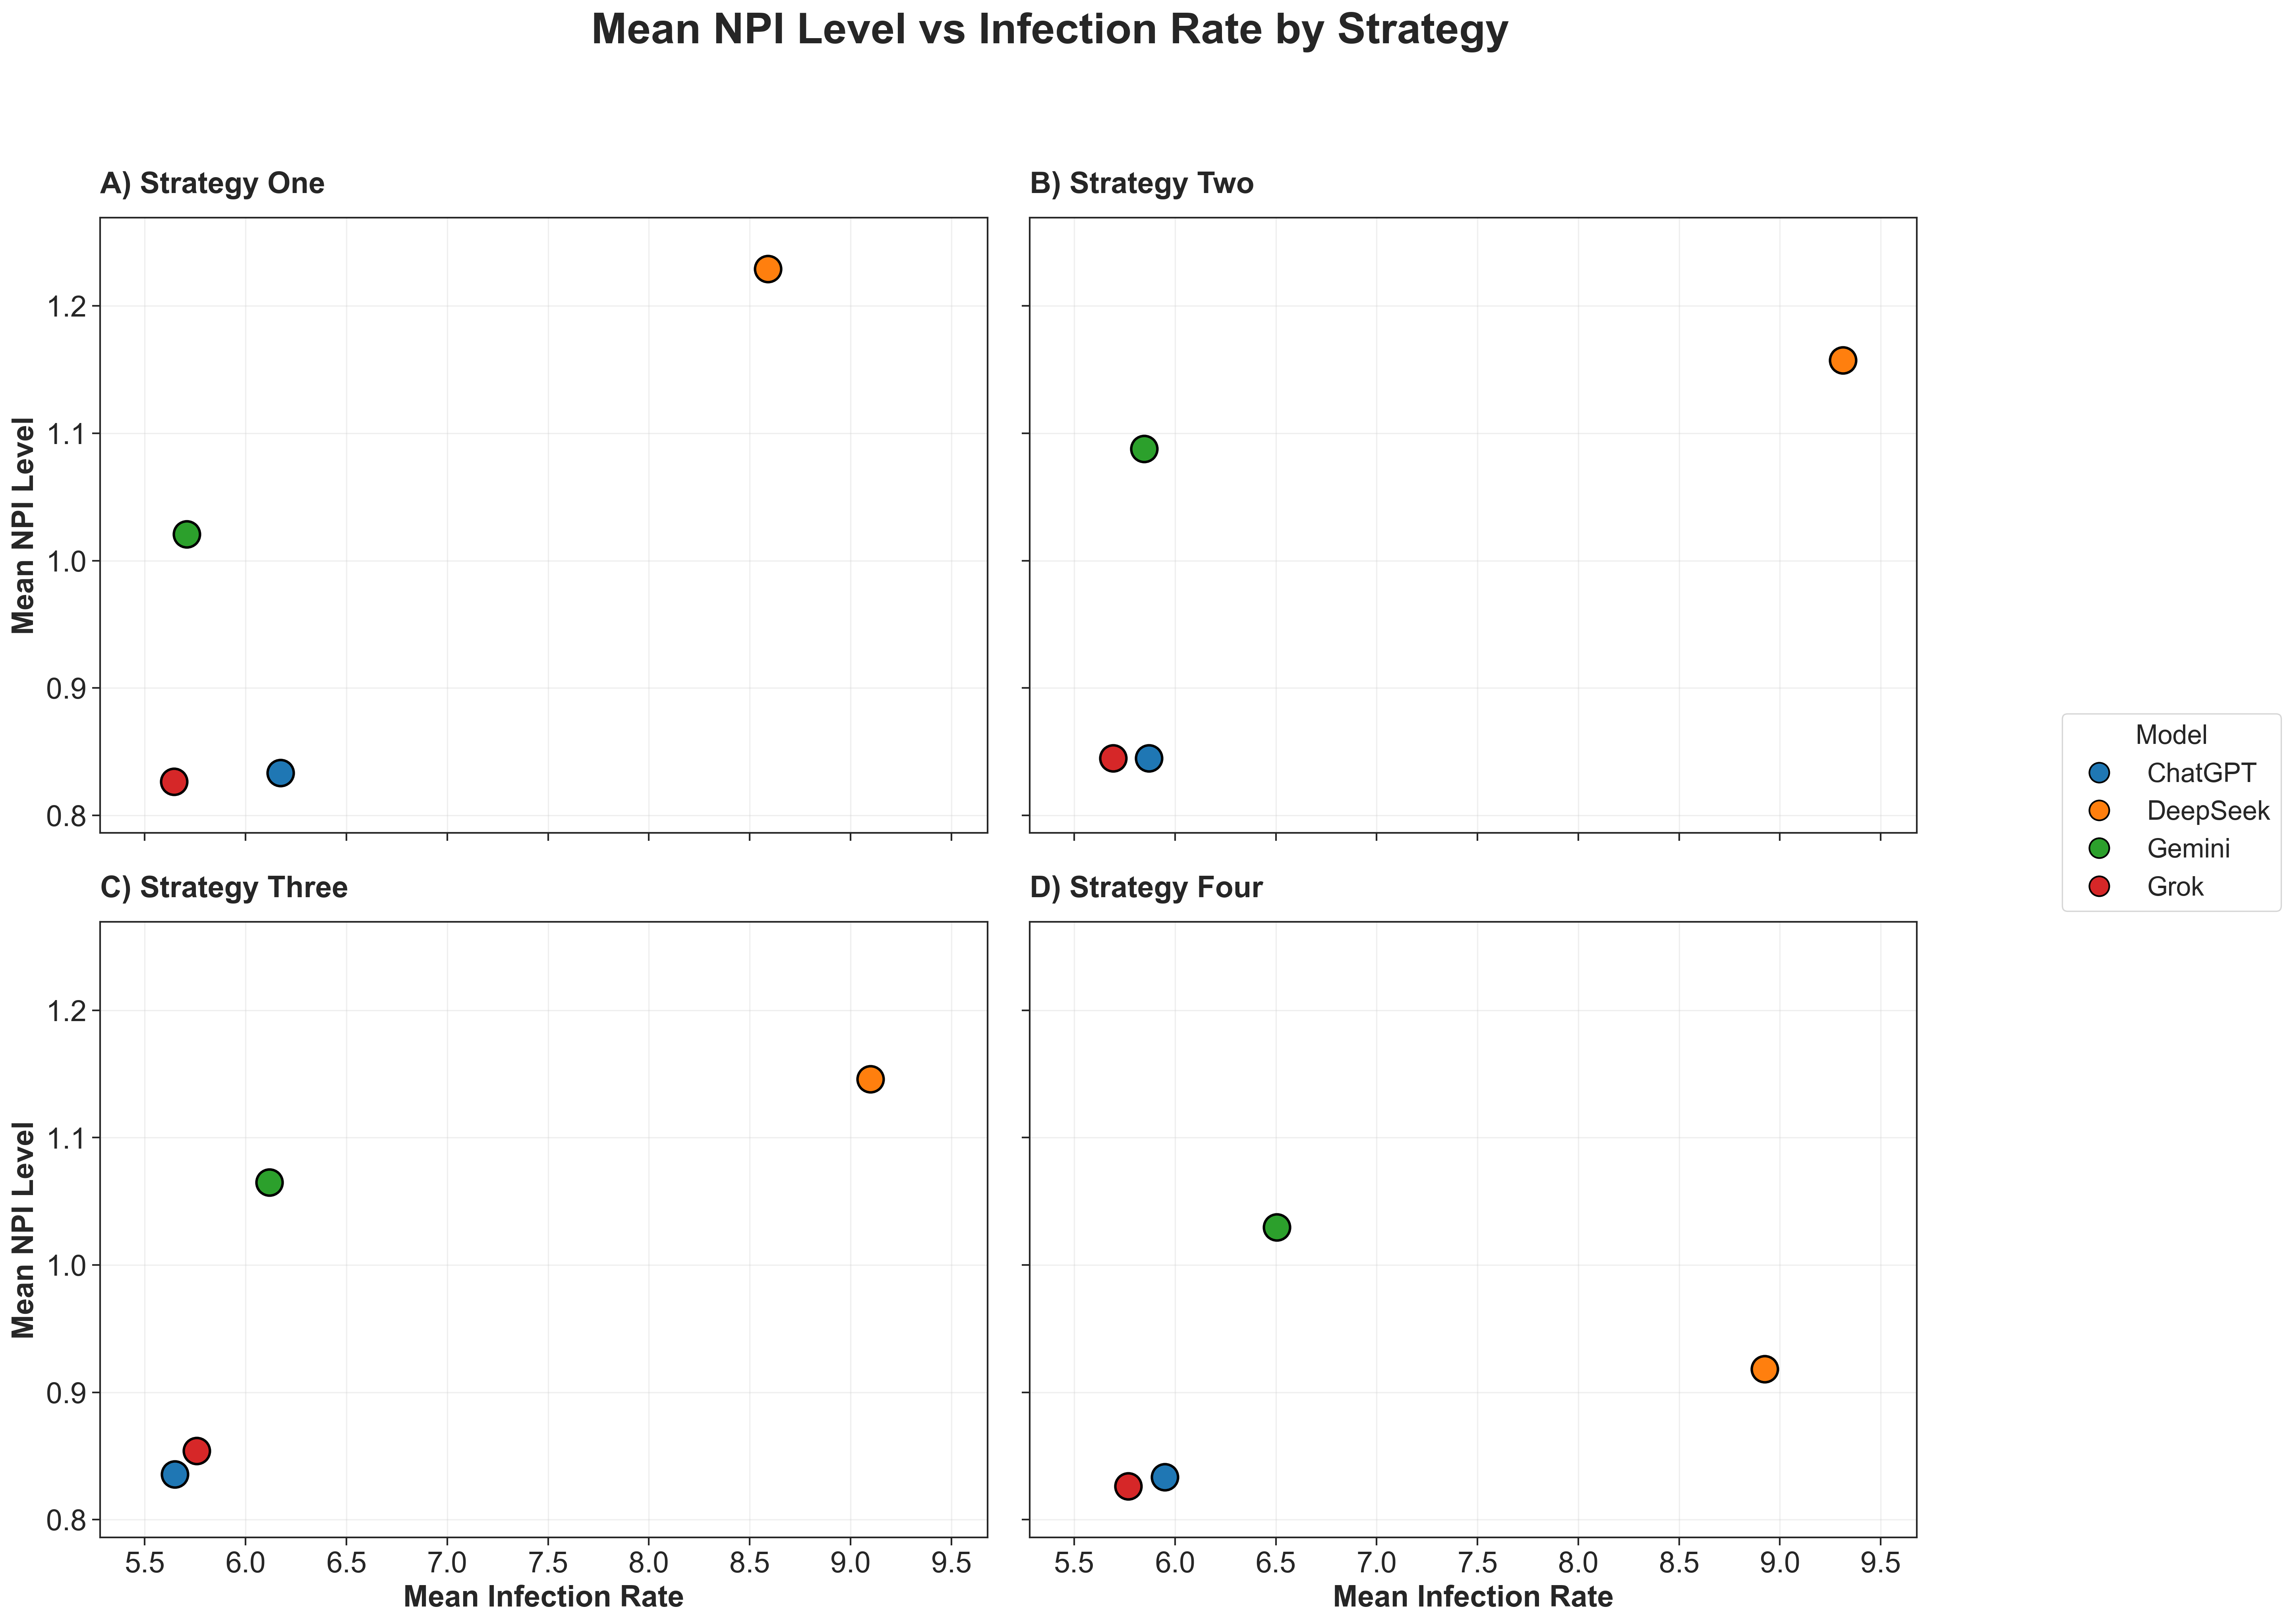

In [16]:
def plot_scatter_combined(df, x_col='infection_rate_selected', y_col='npi_level_selected'):
    """Figure 4: Scatter plot. Shared axes."""
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    all_means = df.groupby(['strategy', 'model'])[[x_col, y_col]].mean()
    x_min, x_max = all_means[x_col].min(), all_means[x_col].max()
    y_min, y_max = all_means[y_col].min(), all_means[y_col].max()
    
    pad_x = (x_max - x_min) * 0.1 if x_max != x_min else 0.1
    pad_y = (y_max - y_min) * 0.1 if y_max != y_min else 0.1
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()
    
    for idx, strategy in enumerate(strategies):
        ax = axes_flat[idx]
        strategy_data = df[df['strategy'] == strategy]
        
        means = strategy_data.groupby('model')[[x_col, y_col]].mean().reset_index()
        
        for _, row in means.iterrows():
            model = row['model']
            ax.scatter(
                row[x_col], row[y_col],
                s=250,
                c=[MODEL_COLORS[model]],
                edgecolor='black', linewidth=1.5,
                label=model,
                zorder=3
            )
            
        ax.set_title(f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}', fontsize=18, fontweight='bold', loc='left', pad=15)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(x_min - pad_x, x_max + pad_x)
        ax.set_ylim(y_min - pad_y, y_max + pad_y)
        
        # MODIFIED: Tick params set to default (shared axes automatically hide inner ticks usually)
        # But explicitly ensuring labelbottom/labelleft are controlled if needed
        ax.tick_params(bottom=True, left=True) 

    # MODIFIED: Labels only on outer edges
    # 1. Y-axis labels on the left column only
    if axes.ndim == 1:
         axes[0].set_ylabel('Mean NPI Level', fontsize=18, fontweight='bold')
    else:
        for ax in axes[:, 0]:
            ax.set_ylabel('Mean NPI Level', fontsize=18, fontweight='bold')

    # 2. X-axis labels on the bottom row only
    if axes.ndim == 1:
        bottom_row = axes
    else:
        bottom_row = axes[-1, :]
        
    for ax in bottom_row:
        ax.set_xlabel('Mean Infection Rate', fontsize=18, fontweight='bold')

    sorted_models = sorted(MODEL_COLORS.keys())
    handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=MODEL_COLORS[m], 
                          markersize=12, markeredgecolor='black', label=m) 
               for m in sorted_models]
    
    fig.legend(handles=handles, title='Model', loc='center right', 
               bbox_to_anchor=(1.08, 0.5), fontsize=16, title_fontsize=16)
    
    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)


    fig.suptitle('Mean NPI Level vs Infection Rate by Strategy', fontsize=26, fontweight='bold', y=0.98)


    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    save_publication_figure('fig4_scatter_infection_vs_npi')
    #plt.show()


if not results_df.empty:
    plot_scatter_combined(results_df)


### Figure 5: Context-Stratified Scatter Plot

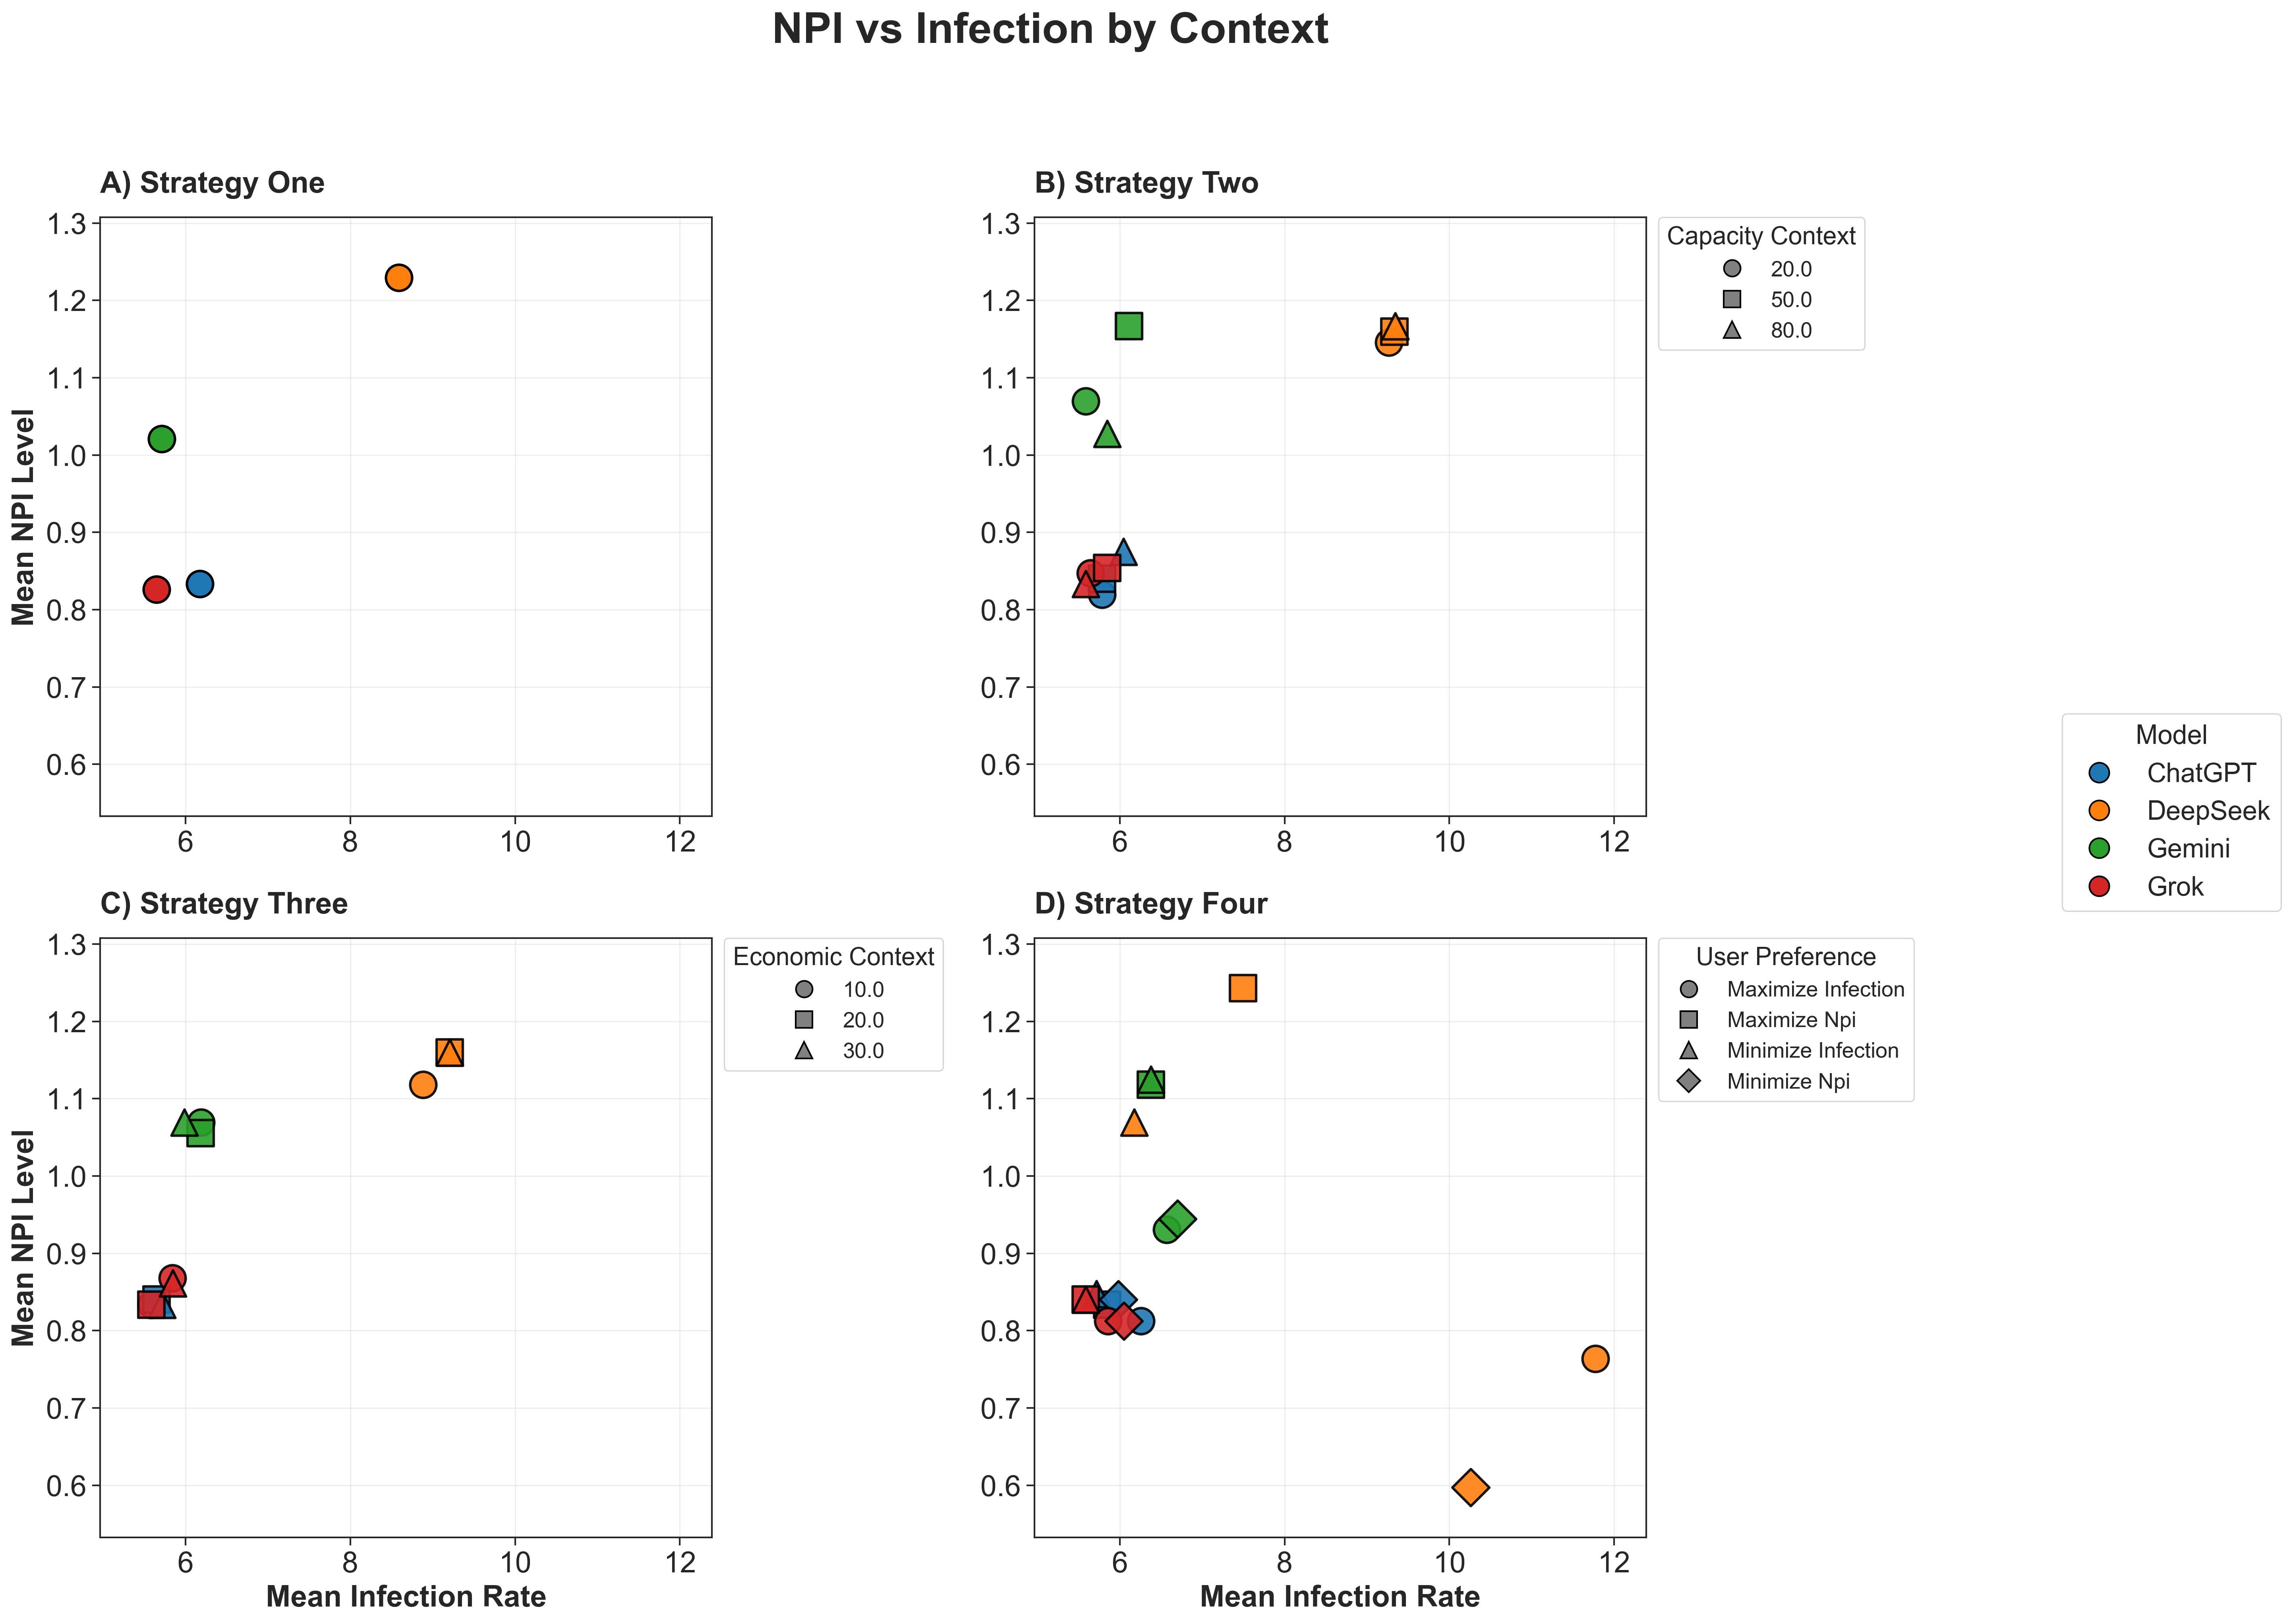

In [17]:
def plot_scatter_with_context(df, x_col='infection_rate_selected', y_col='npi_level_selected'):
    """Figure 5: Scatter plot with Context shapes."""
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    # Calculate limits
    all_mins_x, all_maxs_x = [], []
    all_mins_y, all_maxs_y = [], []
    
    for strategy in strategies:
        s_data = df[df['strategy'] == strategy]
        ctx = get_context_column(strategy)
        group_cols = ['model', ctx] if (ctx and ctx in s_data.columns) else ['model']
        means = s_data.groupby(group_cols)[[x_col, y_col]].mean()
        all_mins_x.append(means[x_col].min())
        all_maxs_x.append(means[x_col].max())
        all_mins_y.append(means[y_col].min())
        all_maxs_y.append(means[y_col].max())
        
    x_min, x_max = min(all_mins_x), max(all_maxs_x)
    y_min, y_max = min(all_mins_y), max(all_maxs_y)
    pad_x = (x_max - x_min) * 0.1
    pad_y = (y_max - y_min) * 0.1



    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()
    markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*', 'h']
    
    # --- Create legends dynamically ---
    # Global legend for models (colors)
    sorted_models = sorted(df['model'].unique())
    model_handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=MODEL_COLORS[m], 
                          markersize=12, markeredgecolor='black', label=m) 
               for m in sorted_models]
    fig.legend(handles=model_handles, title='Model', loc='center right', 
               bbox_to_anchor=(1.08, 0.5), fontsize=16, title_fontsize=16)


    # --- Plotting ---
    for idx, strategy in enumerate(strategies):
        ax = axes_flat[idx]
        strategy_data = df[df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)
        
        ax.set_title(f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}', fontsize=18, fontweight='bold', loc='left', pad=15)
        ax.set_xlim(x_min - pad_x, x_max + pad_x)
        ax.set_ylim(y_min - pad_y, y_max + pad_y)
        ax.grid(True, alpha=0.3)
        
        if context_col and context_col in strategy_data.columns:
            means = strategy_data.groupby(['model', context_col])[[x_col, y_col]].mean().reset_index()
            contexts = sorted(means[context_col].unique())
            ctx_markers = dict(zip(contexts, markers[:len(contexts)]))
            
            for _, row in means.iterrows():
                ax.scatter(
                    row[x_col], row[y_col],
                    s=250, # Increased size to match fig 4
                    c=[MODEL_COLORS[row['model']]],
                    marker=ctx_markers[row[context_col]],
                    edgecolor='black', linewidth=1.5,
                    alpha=0.9
                )
            
            # --- Context Legend (Shapes) ---
            # This legend is created for EACH subplot that has context, but placed outside.
            ctx_handles = [plt.Line2D([0],[0], marker=ctx_markers[c], color='w', markerfacecolor='gray', 
                                      markersize=10, markeredgecolor='black', label=str(c).replace('_',' ').title()) 
                           for c in contexts]
            legend_title = get_legend_title(context_col)
            
            # Place context legend outside the plot area
            ax.legend(handles=ctx_handles, title=legend_title, loc='upper left', 
                      bbox_to_anchor=(1.02, 1), borderaxespad=0., fontsize=13, title_fontsize=15)


        else: # Strategy 1 (no context)
            means = strategy_data.groupby('model')[[x_col, y_col]].mean().reset_index()
            for _, row in means.iterrows():
                ax.scatter(
                    row[x_col], row[y_col],
                    s=250,
                    c=[MODEL_COLORS[row['model']]],
                    marker='o',
                    edgecolor='black', linewidth=1.5
                )
        
        # Force labels on all panels
        ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)
        # Removed repetitive setting of xlabel/ylabel inside loop
    
    # MODIFIED: Labels ONLY on the bottom/left panels
    # 1. Y-axis labels on the left column only
    if axes.ndim == 1:
         axes[0].set_ylabel('Mean NPI Level', fontsize=18, fontweight='bold')
    else:
        for ax in axes[:, 0]:
            ax.set_ylabel('Mean NPI Level', fontsize=18, fontweight='bold')

    # 2. X-axis labels on the bottom row only
    if axes.ndim == 1:
        bottom_row = axes
    else:
        bottom_row = axes[-1, :]
        
    for ax in bottom_row:
        ax.set_xlabel('Mean Infection Rate', fontsize=18, fontweight='bold')

    for idx in range(n_strategies, len(axes_flat)): axes_flat[idx].set_visible(False)


    fig.suptitle('NPI vs Infection by Context', fontsize=26, fontweight='bold', y=0.98)
    
    # Match layout padding with Figure 4
    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    save_publication_figure('fig5_scatter_context')
    #plt.show()


if not results_df.empty:
    plot_scatter_with_context(results_df)


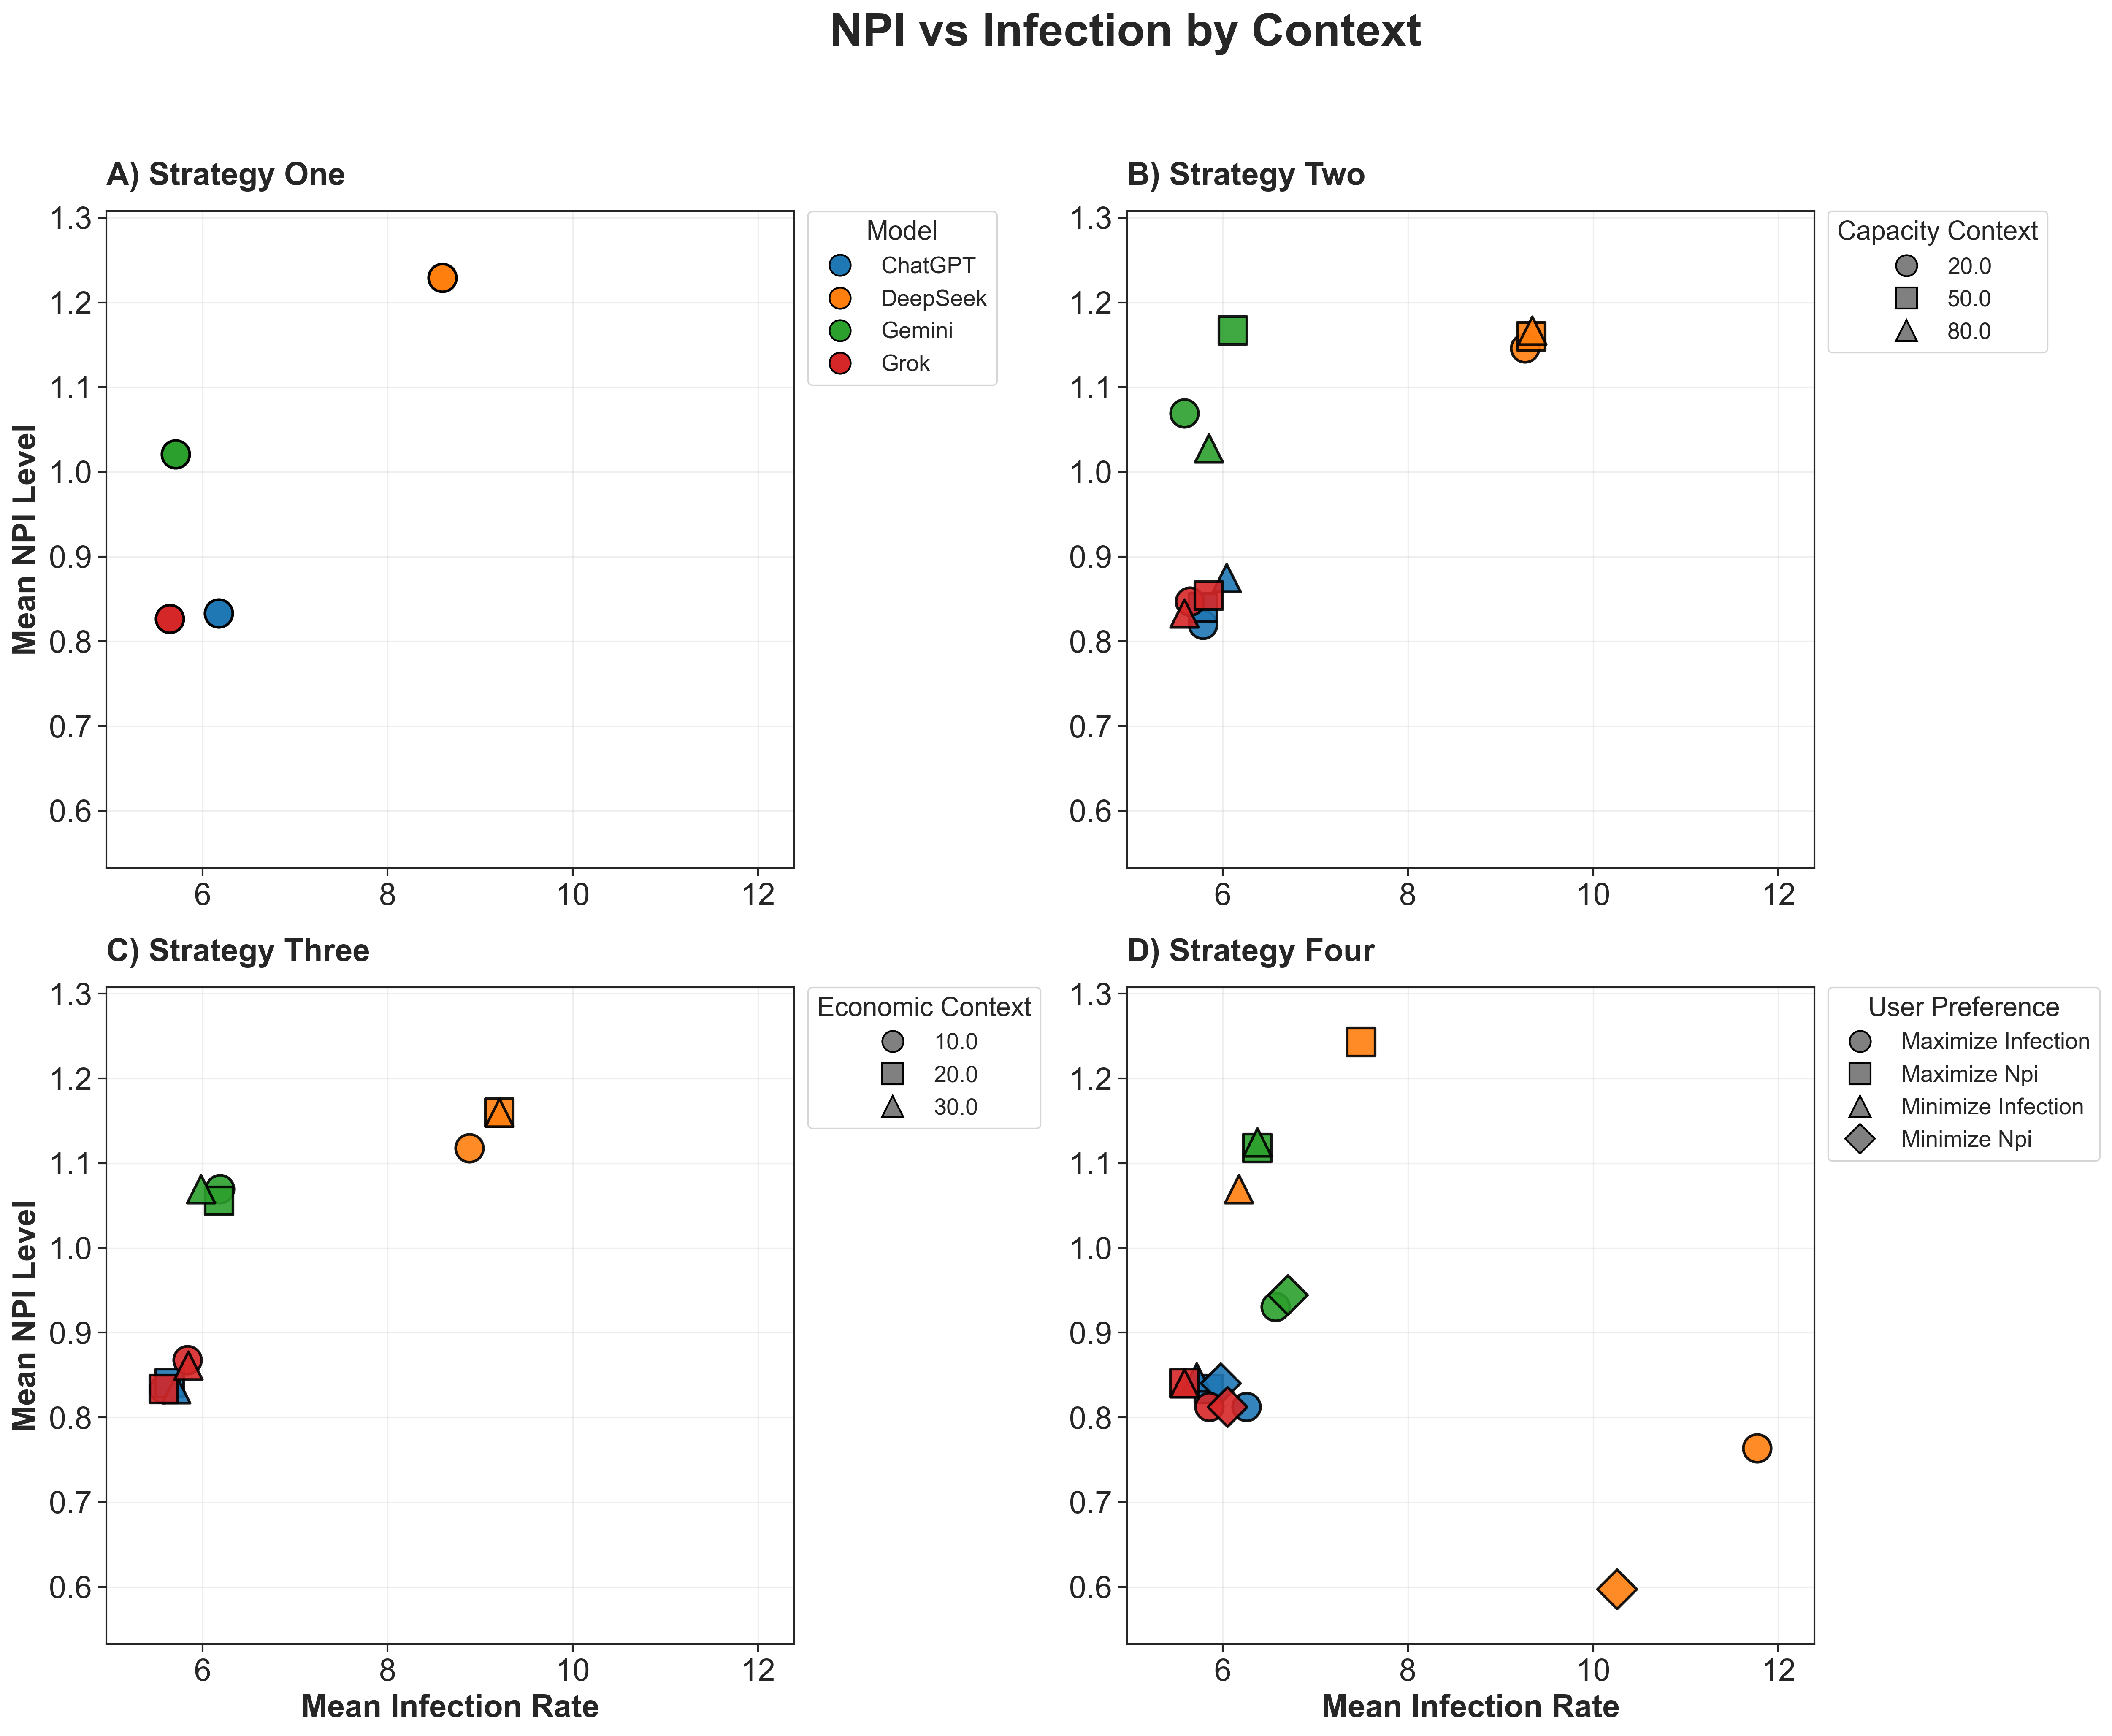

In [18]:
def plot_scatter_with_context(df, x_col='infection_rate_selected', y_col='npi_level_selected'):
    """Figure 5: Scatter plot with Context shapes."""
    # Global font settings for readability
    plt.rcParams['font.size'] = 14  # base font size [web:8][web:12]

    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))

    # ---- Compute global axis limits ----
    all_mins_x, all_maxs_x = [], []
    all_mins_y, all_maxs_y = [], []

    for strategy in strategies:
        s_data = df[df['strategy'] == strategy]
        ctx = get_context_column(strategy)
        group_cols = ['model', ctx] if (ctx and ctx in s_data.columns) else ['model']
        means = s_data.groupby(group_cols)[[x_col, y_col]].mean()
        all_mins_x.append(means[x_col].min())
        all_maxs_x.append(means[x_col].max())
        all_mins_y.append(means[y_col].min())
        all_maxs_y.append(means[y_col].max())

    x_min, x_max = min(all_mins_x), max(all_maxs_x)
    y_min, y_max = min(all_mins_y), max(all_maxs_y)
    pad_x = (x_max - x_min) * 0.1
    pad_y = (y_max - y_min) * 0.1

    # ---- Create subplots ----
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=FIG_SIZE_MULTI,
        sharex=True,
        sharey=True
    )  # [web:2][web:19]
    axes_flat = axes.flatten() if np.ndim(axes) > 1 else np.array([axes])
    markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*', 'h']

    # ---- Model legend handles (colors) ----
    sorted_models = sorted(df['model'].unique())
    model_handles = [
        plt.Line2D(
            [0], [0],
            marker='o',
            color='w',
            markerfacecolor=MODEL_COLORS[m],
            markersize=12,
            markeredgecolor='black',
            label=m
        )
        for m in sorted_models
    ]

    # ---- Plot each strategy ----
    for idx, strategy in enumerate(strategies):
        ax = axes_flat[idx]
        strategy_data = df[df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)

        # Panel title
        ax.set_title(
            f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}',
            fontsize=18,
            fontweight='bold',
            loc='left',
            pad=15
        )

        # Shared limits/grid
        ax.set_xlim(x_min - pad_x, x_max + pad_x)
        ax.set_ylim(y_min - pad_y, y_max + pad_y)
        ax.grid(True, alpha=0.3)

        # ---- With context (shapes) ----
        if context_col and context_col in strategy_data.columns:
            means = (
                strategy_data
                .groupby(['model', context_col])[[x_col, y_col]]
                .mean()
                .reset_index()
            )
            contexts = sorted(means[context_col].unique())
            ctx_markers = dict(zip(contexts, markers[:len(contexts)]))

            for _, row in means.iterrows():
                ax.scatter(
                    row[x_col],
                    row[y_col],
                    s=250,
                    c=[MODEL_COLORS[row['model']]],
                    marker=ctx_markers[row[context_col]],
                    edgecolor='black',
                    linewidth=1.5,
                    alpha=0.9
                )

            # Context legend (shapes) for this panel only, outside the axes
            ctx_handles = [
                plt.Line2D(
                    [0], [0],
                    marker=ctx_markers[c],
                    color='w',
                    markerfacecolor='gray',
                    markersize=12,
                    markeredgecolor='black',
                    label=str(c).replace('_', ' ').title()
                )
                for c in contexts
            ]
            legend_title = get_legend_title(context_col)
            ax.legend(
                handles=ctx_handles,
                title=legend_title,
                loc='upper left',
                bbox_to_anchor=(1.02, 1.0),
                borderaxespad=0.0,
                fontsize=13,
                title_fontsize=15,
                frameon=True
            )  # [web:20][web:23][web:28]

        # ---- No context (Strategy 1) ----
        else:
            means = (
                strategy_data
                .groupby('model')[[x_col, y_col]]
                .mean()
                .reset_index()
            )
            for _, row in means.iterrows():
                ax.scatter(
                    row[x_col],
                    row[y_col],
                    s=250,
                    c=[MODEL_COLORS[row['model']]],
                    marker='o',
                    edgecolor='black',
                    linewidth=1.5
                )

        # Tick labels on all panels (axis labels handled below)
        ax.tick_params(
            bottom=True,
            left=True,
            labelbottom=True,
            labelleft=True
        )

        # ---- Add Model legend ONLY for Strategy 1 (first/top-left panel), outside ----
        if idx == 0:
            ax.legend(
                handles=model_handles,
                title='Model',
                loc='upper left',           # anchor legend's left-center
                bbox_to_anchor=(1.02, 1.0),  # to the right of the axes, vertically centered
                borderaxespad=0.0,
                fontsize=13,
                title_fontsize=15,
                frameon=True
            )  # [web:19][web:21][web:28]

    # Hide unused axes if any
    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # ---- Axis labels (bottom row / left column only) ----
    if np.ndim(axes) == 1:
        axes[0].set_ylabel('Mean NPI Level', fontsize=18, fontweight='bold')
        axes[-1].set_xlabel('Mean Infection Rate', fontsize=18, fontweight='bold')
    else:
        for ax in axes[:, 0]:
            ax.set_ylabel('Mean NPI Level', fontsize=18, fontweight='bold')
        for ax in axes[-1, :]:
            if ax.get_visible():
                ax.set_xlabel('Mean Infection Rate', fontsize=18, fontweight='bold')

    # ---- Figure title and layout ----
    fig.suptitle(
        'NPI vs Infection by Context',
        fontsize=26,
        fontweight='bold',
        y=0.98
    )
    # Extra right margin to accommodate legends next to Strategy 1
    plt.tight_layout(rect=[0, 0, 0.94, 0.95])  # [web:2][web:25]

    save_publication_figure('fig5_scatter_context')
    # plt.show()


if not results_df.empty:
    plot_scatter_with_context(results_df)
